## 1. Description du Modèle (Protocole ODD)

### Phénomène à modéliser
Dans les sociétés modernes, l'opinion publique se forme par les interactions entre individus. À l'aide d'un SMA, nous étudions comment ces interactions locales peuvent produire un consensus, une polarisation ou des groupes d'opinion.

### Overview (Vue d'ensemble)
* **Objectif :** Simuler l'évolution des opinions individuelles dans une population afin d'étudier l'émergence de consensus, de polarisation ou de groupes d'opinion.
* **Entités :** Les agents représentent des individus.
* **Variables d'état :** L'opinion $o_i \in [0,1]$ (0 = totalement contre, 0.5 = neutre, 1 = totalement pour).
* **Processus :** À chaque tick, un agent observe les opinions de ses voisins $\mathcal{N}_i$, calcule leur moyenne $\bar{o}_{\mathcal{N}_i}^{\,t}$, et ajuste son opinion :
  $o_i^{t+1}=o_i^t+\alpha\left(\bar{o}_{\mathcal{N}_i}^{\,t}-o_i^t\right)$ avec $\alpha\in[0,1]$.

### Design Concepts
* **Émergence :** Consensus, polarisation ou clusters émergent sans coordination centrale.
* **Interaction :** Chaque agent s'ajuste en fonction de l'opinion de ses voisins.
* **Adaptation / Stochasticité :** L'opinion initiale est aléatoire. Les agents s'adaptent sous influence sociale.
* **Observation :** Opinion moyenne, variance (dispersion), nombre de clusters, vitesse de convergence.

### Details
* **Initialisation :** $N$ agents sur une grille. Initialisation aléatoire de $o_i$ et définition de l'influence $\alpha$.
* **Données d'entrée :** $N$ (population), taille de la grille, paramètre d'influence $\alpha$, durée de la simulation.

In [ ]:
pip install mesa numpy matplotlib pandas

In [ ]:
# Importation des bibliothèques nécessaires
import mesa
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Configuration de l'affichage des graphiques
%matplotlib inline

## 2. Implémentation de l'Agent

L'agent `CitizenAgent` possède une variable d'état `opinion`. À chaque itération (`step`), il récupère la liste de ses voisins sur la grille, calcule la moyenne de leurs opinions, et rapproche sa propre opinion de cette moyenne proportionnellement à son coefficient d'influence $\alpha$.

In [ ]:
class CitizenAgent(mesa.Agent):
    """Un individu ayant une opinion qui évolue selon ses voisins."""
    def __init__(self, model, alpha):
        # Initialisation de l'agent (l'enregistrement dans le modèle est automatique dans Mesa 3)
        super().__init__(model)

        # Opinion initiale tirée aléatoirement entre 0 et 1
        self.opinion = self.model.random.random()
        # Niveau d'influence sociale
        self.alpha = alpha

    def step(self):
        # Récupération des voisins (Moore = 8 voisins alentours, sans inclure le centre)
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False)

        if len(neighbors) > 0:
            # Calcul de l'opinion moyenne des voisins
            mean_opinion = np.mean([neighbor.opinion for neighbor in neighbors])

            # Mise à jour de l'opinion selon la formule mathématique du TD
            self.opinion = self.opinion + self.alpha * (mean_opinion - self.opinion)

## 3. Implémentation du Modèle

Le modèle `OpinionModel` initialise l'espace (une grille `MultiGrid`), peuple cette grille avec nos agents, et gère le déroulement du temps et la collecte des données.

In [ ]:
class OpinionModel(mesa.Model):
    """Modèle simulant la formation de l'opinion publique sur une grille."""
    def __init__(self, width, height, alpha=0.2, seed=None):
        super().__init__(seed=seed)

        # Espace discret (grille) avec bords communicants (torus=True)
        self.grid = mesa.space.MultiGrid(width, height, torus=True)
        self.alpha = alpha

        # Initialisation de la population : on place un agent par case
        for _, pos in self.grid.coord_iter():   # ✅ Correction ici
            agent = CitizenAgent(self, self.alpha)
            self.grid.place_agent(agent, pos)

        # Mise en place du collecteur de données pour l'observation
        self.datacollector = mesa.DataCollector(
            model_reporters={
                "Opinion Moyenne": lambda m: np.mean([a.opinion for a in m.agents]),
                "Variance (Dispersion)": lambda m: np.var([a.opinion for a in m.agents])
            },
            agent_reporters={
                "Opinion": "opinion"
            }
        )

    def step(self):
        # 1. Collecter les données de l'état actuel
        self.datacollector.collect(self)
        # 2. Activer tous les agents dans un ordre aléatoire (Syntaxe Mesa 3)
        self.agents.shuffle_do("step")

## 4. Exécution de la simulation et Observation

Nous allons maintenant instancier notre modèle, le faire tourner pendant un certain nombre de ticks, et observer l'évolution globale (la moyenne et la dispersion) ainsi que l'évolution individuelle pour identifier l'émergence d'un consensus ou de groupes.

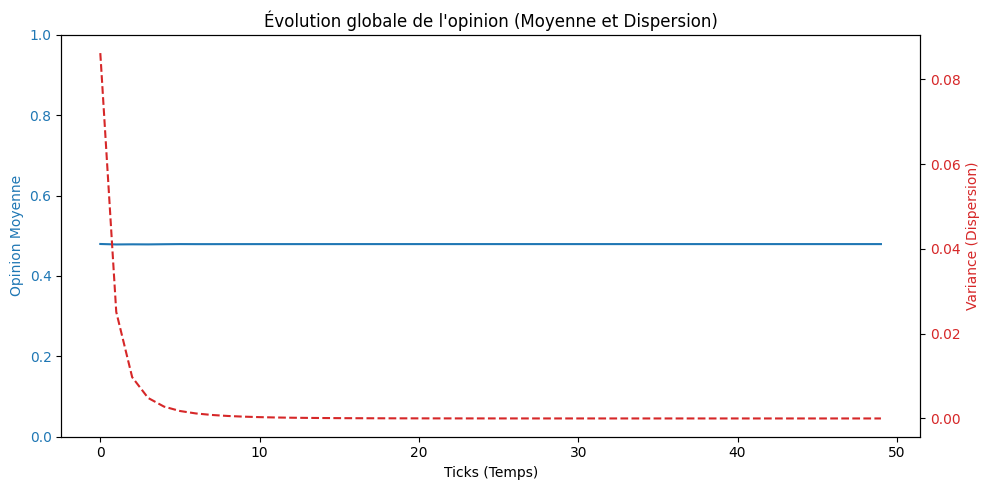

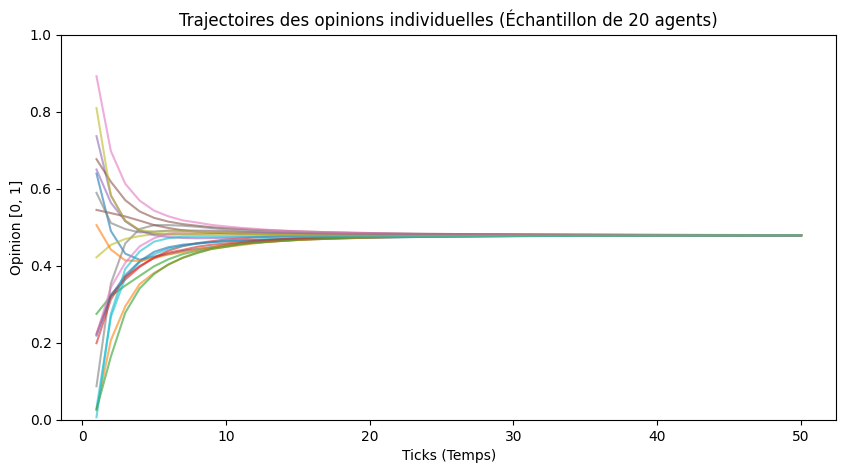

In [ ]:
# Paramètres du modèle
WIDTH = 10
HEIGHT = 10
ALPHA = 0.5  # Modifiez alpha pour observer son impact sur la vitesse de convergence
STEPS = 50

# Création et exécution du modèle
model = OpinionModel(width=WIDTH, height=HEIGHT, alpha=ALPHA, seed=42)

for i in range(STEPS):
    model.step()

# Récupération des données collectées
model_data = model.datacollector.get_model_vars_dataframe()
agent_data = model.datacollector.get_agent_vars_dataframe()

# Affichage des résultats globaux (Moyenne et Variance)
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Ticks (Temps)')
ax1.set_ylabel('Opinion Moyenne', color=color)
ax1.plot(model_data.index, model_data['Opinion Moyenne'], color=color, label="Moyenne")
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 1)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Variance (Dispersion)', color=color)
ax2.plot(model_data.index, model_data['Variance (Dispersion)'], color=color, linestyle='--', label="Variance")
ax2.tick_params(axis='y', labelcolor=color)

plt.title("Évolution globale de l'opinion (Moyenne et Dispersion)")
fig.tight_layout()
plt.show()

# Affichage des trajectoires individuelles (Polarisation vs Consensus)
# On prend un échantillon de 20 agents pour la lisibilité
agent_opinions = agent_data.unstack(level=1)['Opinion']
sample_agents = agent_opinions.columns[:20]

plt.figure(figsize=(10, 5))
for agent_id in sample_agents:
    plt.plot(agent_opinions.index, agent_opinions[agent_id], alpha=0.6)

plt.title("Trajectoires des opinions individuelles (Échantillon de 20 agents)")
plt.xlabel("Ticks (Temps)")
plt.ylabel("Opinion [0, 1]")
plt.ylim(0, 1)
plt.show()

## 5. Questions d'analyse et de compréhension

**Compréhension théorique (Dynamique des systèmes complexes)**
* Quel est l'impact précis du paramètre d'influence $\alpha$ sur la vitesse de convergence globale ? Que se passe-t-il visuellement sur le graphique si $\alpha$ est très proche de 0, ou à l'inverse, égal à 1 ?
* Dans le modèle actuel, le système finit presque toujours par converger vers un consensus global. Quel mécanisme mathématique de la méthode `step()` (mise à jour de l'opinion) rend la polarisation ou la création de groupes impossible à long terme avec cette configuration exacte ?
* En vous basant sur le protocole ODD, expliquez avec vos propres mots comment la notion d'"émergence" se manifeste dans les graphiques que vous avez générés.

**Technique et manipulation de Mesa 3**
* Comment l'activation des agents est-elle gérée dans la nouvelle syntaxe de Mesa 3 (`self.agents.shuffle_do("step")`) par rapport aux itérations classiques sur des listes ? Quel est l'intérêt de l'ordre aléatoire ici ?
* Expliquez la différence entre `model_reporters` et `agent_reporters` lors de l'instanciation du `DataCollector`. Pourquoi est-il indispensable d'utiliser les deux pour observer à la fois le consensus et la dispersion ?
* Si un agent se trouve sur le bord de la grille (par exemple en `x=0`), comment le paramètre `torus=True` du `MultiGrid` affecte-t-il la récupération de ses voisins ?

**Ouverture et esprit critique (Pour aller plus loin)**
* Comment modifieriez-vous le code de l'agent pour introduire un "biais de confirmation" (c'est-à-dire qu'un agent n'est influencé par un voisin que si l'écart entre leurs deux opinions est inférieur à un seuil de tolérance $\epsilon$) ? Quel phénomène social émergerait alors ?
* Si nous devions modéliser un véritable réseau social (comme un graphe d'abonnés) plutôt qu'une grille spatiale, quelle structure topologique de Mesa utiliseriez-vous pour modéliser des "influenceurs" très connectés face à des utilisateurs isolés ?

/usr/local/lib/python3.13/dist-packages/mesa/mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


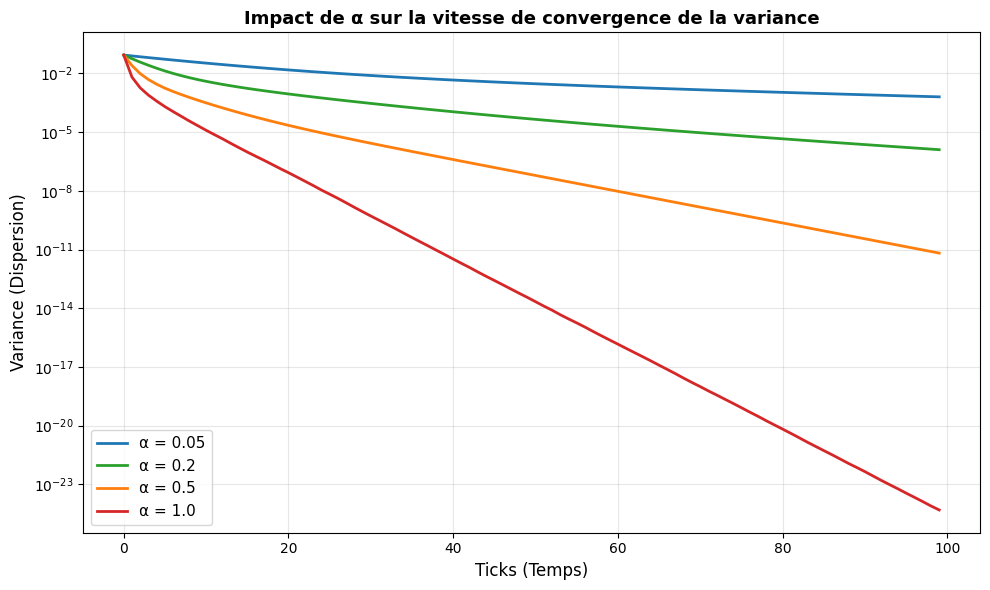

/usr/local/lib/python3.13/dist-packages/mesa/mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/mesa/mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


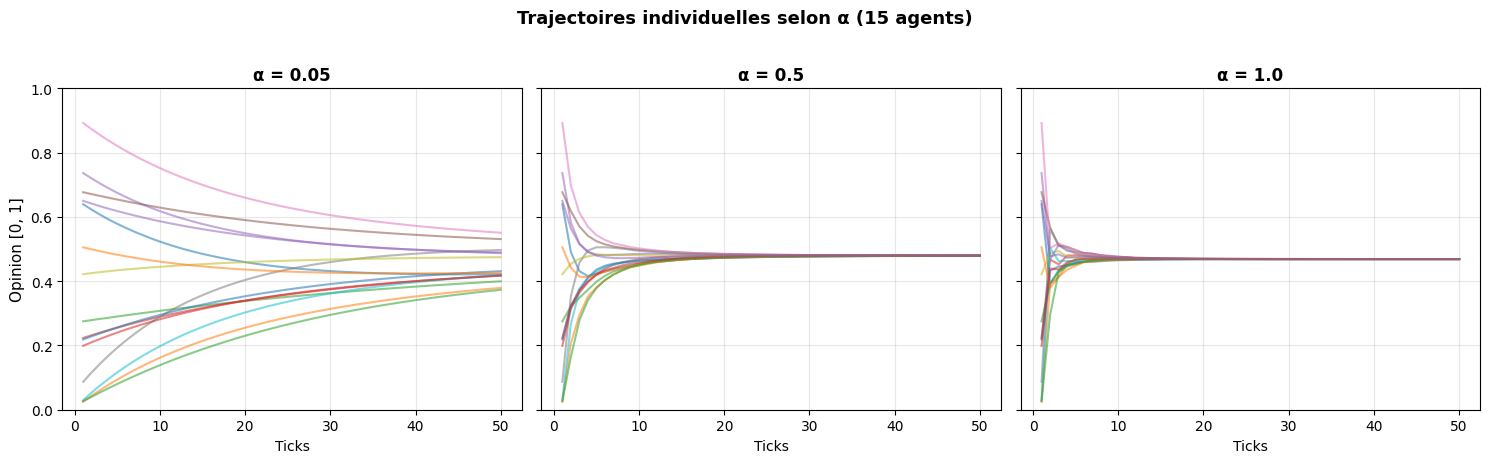

/usr/local/lib/python3.13/dist-packages/mesa/mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


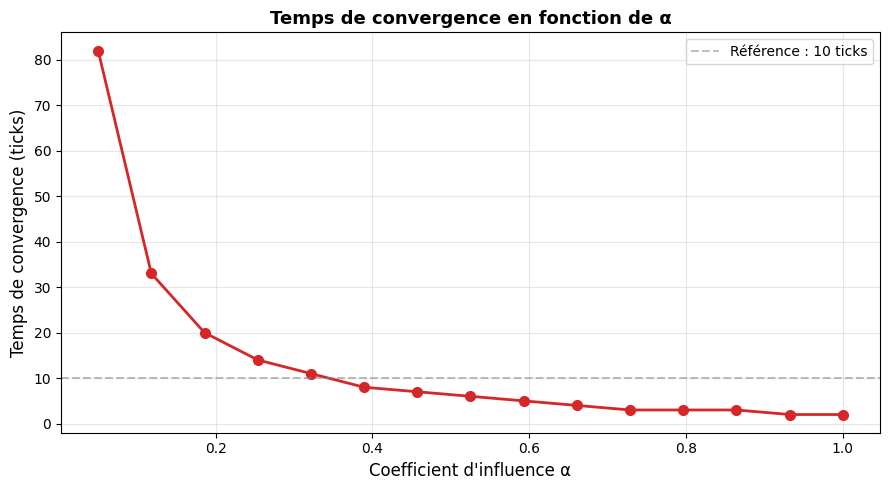


TABLEAU RÉCAPITULATIF — Impact de α
α       Var. init.    Var. finale   Temps conv.   
------------------------------------------------------------
0.05    0.0862        0.0006        83            
0.2     0.0862        0.0000        20            
0.5     0.0862        0.0000        7             
1.0     0.0862        0.0000        3             


In [ ]:
import mesa
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# (Réutiliser les classes CitizenAgent et OpinionModel définies précédemment)

# ============================================================
# FIGURE A : Comparaison des variances pour plusieurs alpha
# ============================================================
alphas = [0.05, 0.2, 0.5, 1.0]
colors = ['#1f77b4', '#2ca02c', '#ff7f0e', '#d62728']
STEPS = 100

plt.figure(figsize=(10, 6))
results = {}
for a, c in zip(alphas, colors):
    model = OpinionModel(10, 10, alpha=a, seed=42)
    for _ in range(STEPS):
        model.step()
    data = model.datacollector.get_model_vars_dataframe()
    results[a] = data
    plt.plot(data.index, data['Variance (Dispersion)'],
             color=c, linewidth=2, label=f'α = {a}')

plt.xlabel('Ticks (Temps)', fontsize=12)
plt.ylabel('Variance (Dispersion)', fontsize=12)
plt.title("Impact de α sur la vitesse de convergence de la variance",
          fontsize=13, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.yscale('log')  # échelle log pour mieux voir la décroissance
plt.tight_layout()
plt.savefig('graphique_alpha_variance.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================
# FIGURE B : Trajectoires individuelles pour alpha = 0.05 vs 0.5 vs 1.0
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, a in zip(axes, [0.05, 0.5, 1.0]):
    model = OpinionModel(10, 10, alpha=a, seed=42)
    for _ in range(50):
        model.step()
    agent_data = model.datacollector.get_agent_vars_dataframe()
    opinions = agent_data.unstack(level=1)['Opinion']
    for agent_id in opinions.columns[:15]:
        ax.plot(opinions.index, opinions[agent_id], alpha=0.55)
    ax.set_title(f'α = {a}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Ticks')
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)

axes[0].set_ylabel('Opinion [0, 1]', fontsize=11)
fig.suptitle("Trajectoires individuelles selon α (15 agents)",
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('graphique_alpha_trajectoires.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================
# FIGURE C : Temps de convergence en fonction de alpha (courbe)
# ============================================================
alphas_fine = np.linspace(0.05, 1.0, 15)
convergence_times = []
threshold = 0.001  # variance considérée comme nulle

for a in alphas_fine:
    model = OpinionModel(10, 10, alpha=a, seed=42)
    conv_time = None
    for t in range(200):
        model.step()
        var = np.var([ag.opinion for ag in model.agents])
        if var < threshold:
            conv_time = t
            break
    convergence_times.append(conv_time if conv_time else 200)

plt.figure(figsize=(9, 5))
plt.plot(alphas_fine, convergence_times, 'o-',
         color='#d62728', linewidth=2, markersize=7)
plt.xlabel('Coefficient d\'influence α', fontsize=12)
plt.ylabel('Temps de convergence (ticks)', fontsize=12)
plt.title("Temps de convergence en fonction de α",
          fontsize=13, fontweight='bold')
plt.grid(alpha=0.3)
plt.axhline(y=10, color='gray', linestyle='--', alpha=0.5,
            label='Référence : 10 ticks')
plt.legend()
plt.tight_layout()
plt.savefig('graphique_alpha_convergence.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================
# Tableau récapitulatif
# ============================================================
print("\n" + "="*60)
print("TABLEAU RÉCAPITULATIF — Impact de α")
print("="*60)
print(f"{'α':<8}{'Var. init.':<14}{'Var. finale':<14}{'Temps conv.':<14}")
print("-"*60)
for a in alphas:
    data = results[a]
    var_init = data['Variance (Dispersion)'].iloc[0]
    var_final = data['Variance (Dispersion)'].iloc[-1]
    conv = next((i for i, v in enumerate(data['Variance (Dispersion)'])
                 if v < 0.001), '>100')
    print(f"{a:<8}{var_init:<14.4f}{var_final:<14.4f}{str(conv):<14}")
print("="*60)

A vous ....